# Import Statements

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import FortranFile
import smplotlib
from hmf import MassFunction
from astropy.cosmology import FlatLambdaCDM, Planck18
import pandas as pd


findfont: Failed to find font weight normal, now using 500.


# Path

In [2]:
root = Path("../").resolve()
tree_dir = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/binary_tree_n_progenitors_mh8to14_2_not_mine")
results = root / "Results_600"
zgrid = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/redshift_grid_mh8to14.bin")
models = {"fiducial", "eSFE", "eIMF"}
for model in models:
    print(model, sorted(p.name for p in results.glob(f"{model}_seed*")))


fiducial ['fiducial_seed12345', 'fiducial_seed13579', 'fiducial_seed24680', 'fiducial_seed32889', 'fiducial_seed98765']
eSFE ['eSFE_seed12345', 'eSFE_seed13579', 'eSFE_seed24680', 'eSFE_seed32889', 'eSFE_seed98765']
eIMF ['eIMF_seed12345', 'eIMF_seed13579', 'eIMF_seed24680', 'eIMF_seed32889', 'eIMF_seed98765']


# Mass Function Definitions

In [3]:
Om, Ob, h = 0.30966, 0.04897, 0.6766   # same cosmology as module_constants.f90 and figure7.ipynb
cosmo = FlatLambdaCDM(H0=100*h, Om0=Om, Ob0=Ob, Tcmb0=2.7255)

mass_function = MassFunction(z=4.5, cosmo_model=cosmo,
                            sigma_8=0.811, n=0.965,
                            hmf_model="ST", transfer_model="EH",
                            Mmin=7, Mmax=15, dlog10m=0.01,
                            )

# hmf gives m in Msun/h, so the mass in Msun is m / h (not m * h); densities are per (cMpc/h)^3, so multiply by h^3.
logM_st = np.log10(mass_function.m / h)
# dn/dlnM (not dn/dlog10M) is the normalisation that reproduces the paper's Fig. 9, as in figure7.ipynb (fresh.pdf, Sect. 4).
phi_st = mass_function.dndlnm * h**3
dlogM_tree = 6.0 / 600.0
logM = []
weight = []

# Read Fortran Files

In [4]:
with FortranFile(zgrid, "r") as f:
    _ = f.read_ints(np.int32)
    redshifts = f.read_reals(np.float64)

def single_input_tree(p):
    with FortranFile(p, "r") as f:
        _ = int(f.read_ints(np.int32)[0])
        redshift_index_of_halos = f.read_ints(np.int32)
        mass_halos = f.read_reals(np.float64)
        _ = f.read_ints(np.int32)
        _ = f.read_ints(np.int32)
    return redshift_index_of_halos, mass_halos

def read_mstar(p):
    with FortranFile(p, "r") as f:
        _sfr = f.read_record(np.float64)
        mstar = f.read_record(np.float64)
    return mstar


In [5]:
models = {"fiducial", "eSFE", "eIMF"}
file_names = []
for model in models:
    print(model, sorted(p.name for p in results.glob(f"{model}_seed*")))
    file_names.append(sorted(p.name for p in results.glob(f"{model}_seed*")))

eSFE ['eSFE_seed12345', 'eSFE_seed13579', 'eSFE_seed24680', 'eSFE_seed32889', 'eSFE_seed98765']
fiducial ['fiducial_seed12345', 'fiducial_seed13579', 'fiducial_seed24680', 'fiducial_seed32889', 'fiducial_seed98765']
eIMF ['eIMF_seed12345', 'eIMF_seed13579', 'eIMF_seed24680', 'eIMF_seed32889', 'eIMF_seed98765']


def 

# SMF for one run

In [6]:
z_targets = [5, 6, 7, 8, 9, 10]
z_use = {zt: int(np.argmax(redshifts >= zt)) + 1 for zt in z_targets} 
bins_mstar = np.arange(6, 12.25, 0.5)

In [7]:
{f"{zt}": [int(np.argmax(redshifts >= zt)) + 1 if zt <= 12 else int(np.argmin(np.abs(redshifts - zt))) + 1] for zt in z_targets}   # first snapshot at or above z up to z = 12, then the closest

{'5': [7], '6': [15], '7': [21], '8': [25], '9': [28], '10': [31]}

In [8]:
z_use

{5: 7, 6: 15, 7: 21, 8: 25, 9: 28, 10: 31}

In [9]:
def smf_one_run(results):
    hist_mstar = {z_i: np.zeros(len(bins_mstar) - 1) for z_i in z_use}
    for output in sorted(results.glob("merger_tree_out_*")):
        tree_id = int(output.name.split("_")[-1])
        inp = tree_dir / f"merger_tree_{tree_id:05d}"
        redshift_index_of_halos, mass_halos = single_input_tree(inp)
        mstar = read_mstar(output)
        weight = np.interp(np.log10(mass_halos[0]), logM_st, phi_st) * dlogM_tree
        for z_target, z_index in z_use.items():
            #import pdb; pdb.set_trace()
            index_range = (redshift_index_of_halos == z_index)
            hist_mstar[z_target] += np.histogram(np.log10(mstar[index_range]), bins=bins_mstar, weights=np.full(index_range.sum(), weight))[0]
    return hist_mstar

# All models and Seeds

In [10]:
phi_mstar = {}
for model in models:
    seeds = [smf_one_run(result) for result in sorted(results.glob(f"{model}_seed*"))]
    if not seeds:
        continue
    else:
        phi_mstar[model] = {name: dict(
        obs_mean=np.mean([s[name] for s in seeds], axis=0),
        obs_min=np.min([s[name] for s in seeds], axis=0),
        obs_max=np.max([s[name] for s in seeds], axis=0)) for name in z_use}
    print(model, len(seeds), "runs")
        

eSFE 5 runs
fiducial 5 runs
eIMF 5 runs


# Load Observations

In [11]:
obs = pd.read_csv("../observations_jwst/stellar_mass_function/SMF_observational_data.csv")
mstar_col, phi_col = "log10 M_star [M_sun]", "log10 Phi [ cMpc^-3 dex^-1]"
locol, hicol = "lower uncertainty (log10)", "upper uncertainty (log10)"

survey_marker = {
    "Duncan2014": "o",
    "Navarro-Carrera2023": "s",
    "Song2016": "D",
    "Weibel2024": "^",
    "Bhatawdekar2019": "x",
    "Kikuchihara2020": "p",
    "Stefanon2021": "v",
}

sources = list(obs["Source"].unique())
cmap = plt.get_cmap("tab20")
survey_color = {src: cmap(i / len(sources)) for i, src in enumerate(sources)}

def plot_one_survey(ax, table, source_name):
    marker = survey_marker.get(source_name, "o")
    color = survey_color[source_name]
    M = table[mstar_col].to_numpy()
    logphi = table[phi_col].to_numpy()
    err_lo = table[locol].to_numpy().astype(float)
    err_hi = table[hicol].to_numpy().astype(float)
    err_lo = np.where(err_lo == 999, 0, err_lo)
    err_hi = np.where(err_hi == 999, 0, err_hi)
    ax.errorbar(M, logphi, yerr=[err_lo, err_hi], fmt=marker, color=color, label=source_name, ms=5, lw=0.8)



findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight bold, now using 800.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.


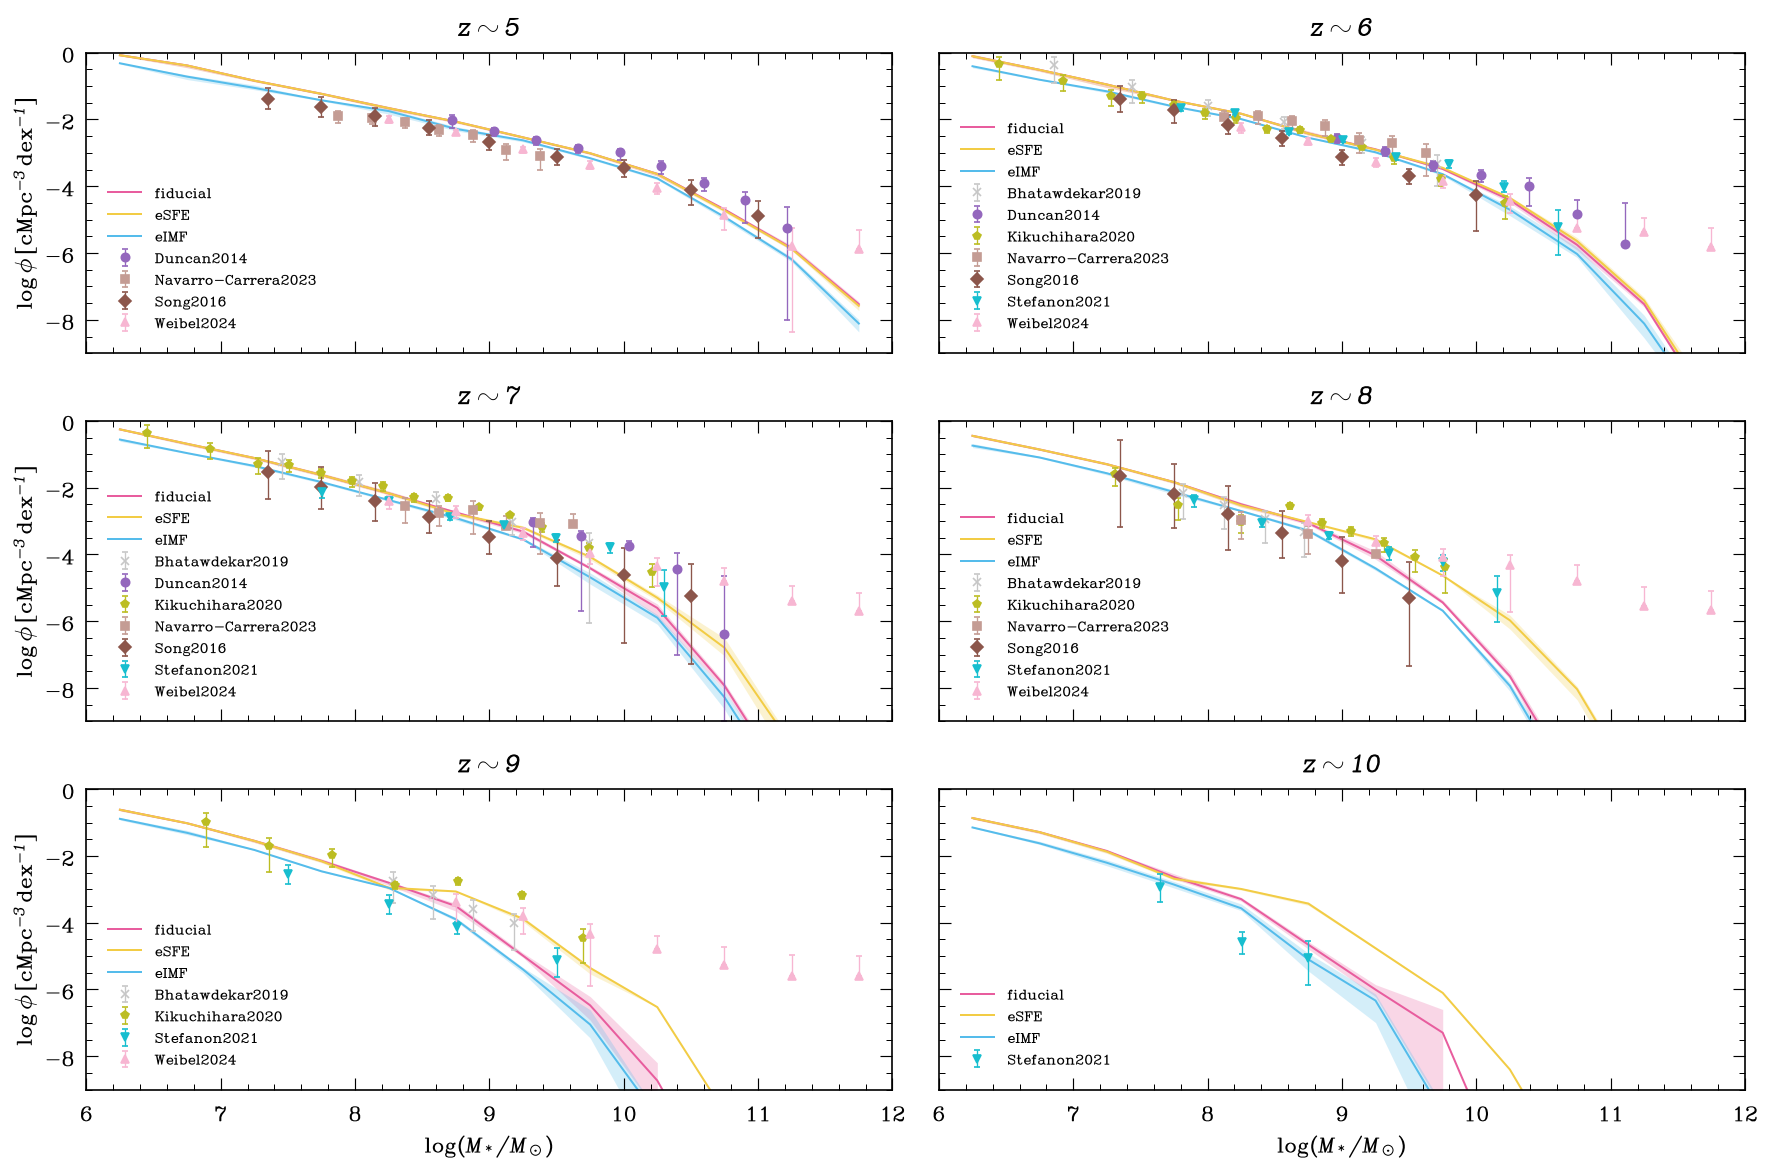

In [12]:
dlogM = np.diff(bins_mstar)
centers = 0.5 * (bins_mstar[:-1] + bins_mstar[1:])
model_color = {"fiducial": "#E85D9E", "eSFE": "#F2CC45", "eIMF": "#55BCEB"}
fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True, sharey=True)
for ax, (z_t, z_i) in zip(axes.ravel(), z_use.items()):
    for model, color in model_color.items():
          ax.plot(centers, np.log10(phi_mstar[model][z_t]["obs_mean"] / dlogM), color=color, label=model)
          ax.fill_between(centers, np.log10(phi_mstar[model][z_t]["obs_min"] /dlogM), np.log10(phi_mstar[model][z_t]["obs_max"] / dlogM), color=color, alpha=0.25, lw=0)
    at_this_z = obs[np.isclose(obs["z"], z_t)]
    for source_name, source_rows in at_this_z.groupby("Source"):
        plot_one_survey(ax, source_rows, source_name)
    ax.set_xlim(6, 12)
    ax.set_ylim(-9, 0)   # as in the paper's Fig. 9
    ax.set_title(rf"$z \sim {redshifts[z_i - 1]:.0f}$")
    ax.legend(frameon=False, fontsize=10, loc=3)

for ax in axes[-1, :]:
    ax.set_xlabel(r"$\log(M_*/M_\odot)$")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\log\phi\,[{\rm cMpc}^{-3}\,{\rm dex}^{-1}]$")
fig.tight_layout()
fig.savefig("smf.png", dpi = 200)
plt.show()